# Artificial Intelligence – Assignment 1 (Version 2)
## Customer Churn Prediction Using Machine Learning

**Course:** Artificial Intelligence  
**Assignment:** Customer Churn Prediction Using Machine Learning  
**Dataset:** Telco Customer Churn  
**Tools:** Python, Pandas, NumPy, Matplotlib, Scikit-learn

### Objective
Build a complete machine-learning pipeline to predict whether a telecom customer will churn. This version follows the required stages: data loading, understanding, preprocessing, EDA, feature engineering, encoding, model training, evaluation, comparison, and sample prediction.

**Version-specific approach:** Version 2 uses Decision Tree and Random Forest. Class weighting is used to give more attention to the minority churn class.


## 1. Import Libraries and Load Dataset
The code works in Google Colab after the CSV is uploaded.

In [1]:
import os, glob, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

DATA_FILE = "WA_Fn-UseC_-Telco-Customer-Churn(1).csv"
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_FILE = next(iter(uploaded.keys()))
    except Exception:
        DATA_FILE = "/mnt/data/WA_Fn-UseC_-Telco-Customer-Churn(1).csv"

df = pd.read_csv(DATA_FILE)
print("Dataset loaded successfully.")
print("Shape:", df.shape)


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset loaded successfully.
Shape: (7043, 21)


## 2. Data Loading and Understanding

In [2]:
print("First five rows:")
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("Data Type"))
print("\nBasic statistics:")
display(df.describe(include="all").T)


First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:


,Data Type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Basic statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Important Columns
- **customerID:** unique customer identifier.
- **tenure:** number of months with the company.
- **InternetService:** type of internet service.
- **Contract:** contract duration.
- **MonthlyCharges:** current monthly bill.
- **TotalCharges:** total amount charged over the customer's tenure.
- **PaymentMethod:** payment method.
- **Churn:** target variable; Yes means the customer left and No means the customer stayed.


## 3. Data Preprocessing and Quality Checks

In [3]:
print("Missing values before cleaning:")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("Missing Values"))
print("Duplicate rows:", df.duplicated().sum())

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("\nMissing values after converting TotalCharges:")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("Missing Values"))

df = df.drop(columns=["customerID"])

if "AvgMonthlySpend" not in df.columns:
    pass

print("\nShape after removing customerID:", df.shape)
display(df["Churn"].value_counts().to_frame("Count"))


Missing values before cleaning:


,Missing Values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Duplicate rows: 0

Missing values after converting TotalCharges:


,Missing Values
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0



Shape after removing customerID: (7043, 20)


,Count
Churn,
No,5174
Yes,1869


### Preprocessing Decisions
1. Convert `TotalCharges` to numeric because blank entries were read as text.
2. Remove `customerID` because it is an identifier rather than a meaningful predictive feature.
3. Handle missing numeric values with median imputation inside the ML pipeline.
4. Encode categorical features using one-hot encoding.
5. No duplicate records are removed because the dataset contains no duplicate rows.


## 4. Exploratory Data Analysis

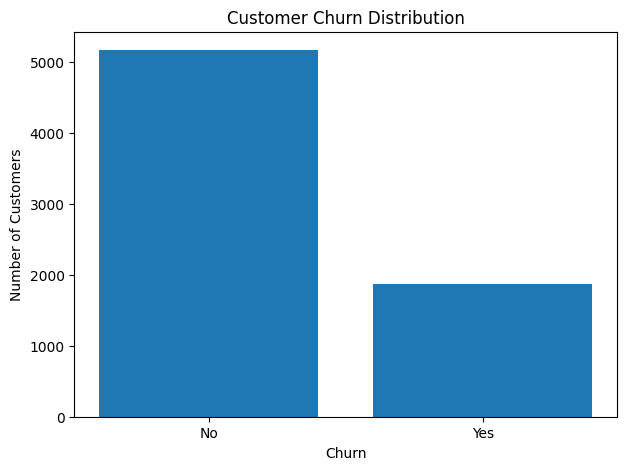

Churn rate by contract type (%):


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


<Figure size 800x500 with 0 Axes>

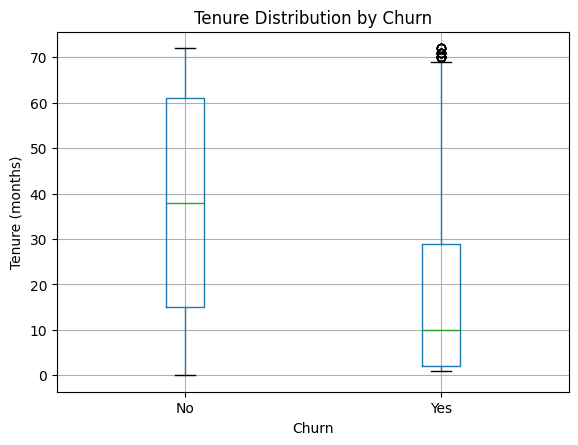

Churn rate by internet service (%):


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [4]:
counts = df["Churn"].value_counts()
plt.figure(figsize=(7,5))
plt.bar(counts.index, counts.values)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
print("Churn rate by contract type (%):")
display(contract_churn.round(2))

plt.figure(figsize=(8,5))
df.boxplot(column="tenure", by="Churn")
plt.title("Tenure Distribution by Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.show()

internet_churn = pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100
print("Churn rate by internet service (%):")
display(internet_churn.round(2))


### EDA Observations
The dataset contains substantially more non-churn customers than churn customers. Contract type, tenure, and internet service show visible differences in churn rates. These are descriptive relationships and do not by themselves prove causation.


## 5. Feature Engineering, Encoding, and Train/Test Split

In [5]:
X = df.drop(columns=["Churn"])
y = (df["Churn"] == "Yes").astype(int)

In [6]:
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numeric_features = X.select_dtypes(exclude=["object"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)

X shape: (7043, 19)
y shape: (7043,)
Training set: (5634, 19)
Testing set: (1409, 19)
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


## 6. Train Two Classification Models

In [7]:
models = {
    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=6, min_samples_leaf=5,
            class_weight="balanced", random_state=42
        ))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=250, max_depth=10,
            class_weight="balanced", random_state=42, n_jobs=-1
        ))
    ])
}

trained_models = {}
predictions = {}
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    trained_models[name] = model
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.7417,0.5086,0.7941,0.6200
1,Random Forest,0.7665,0.5474,0.6952,0.6125


## 7. Model Evaluation

Decision Tree
              precision    recall  f1-score   support

    No Churn     0.9067    0.7227    0.8043      1035
       Churn     0.5086    0.7941    0.6200       374

    accuracy                         0.7417      1409
   macro avg     0.7076    0.7584    0.7122      1409
weighted avg     0.8010    0.7417    0.7554      1409



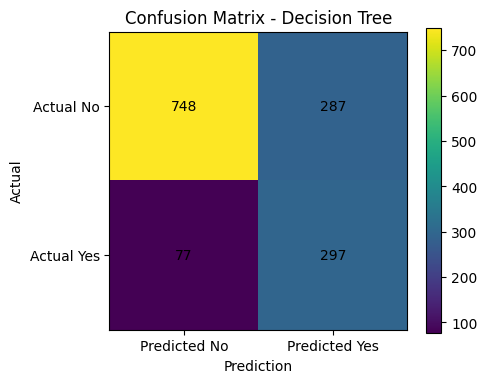

Random Forest
              precision    recall  f1-score   support

    No Churn     0.8779    0.7923    0.8329      1035
       Churn     0.5474    0.6952    0.6125       374

    accuracy                         0.7665      1409
   macro avg     0.7127    0.7437    0.7227      1409
weighted avg     0.7902    0.7665    0.7744      1409



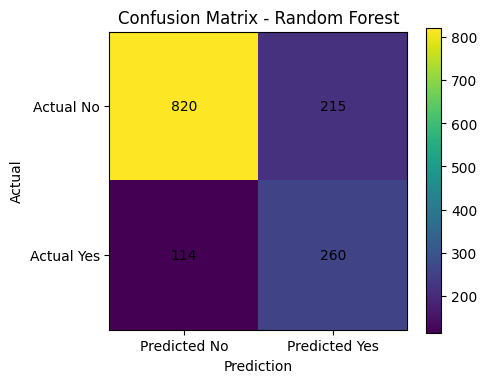

In [8]:
for name, y_pred in predictions.items():
    print("="*60)
    print(name)
    print("="*60)
    print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"], digits=4))
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5,4))
    plt.imshow(cm, interpolation="nearest")
    plt.title(f"Confusion Matrix - {name}")
    plt.colorbar()
    plt.xticks([0,1], ["Predicted No", "Predicted Yes"])
    plt.yticks([0,1], ["Actual No", "Actual Yes"])
    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i,j], ha="center", va="center")
    plt.xlabel("Prediction")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


### Metric Meaning
**Accuracy** measures overall correctness. **Precision** measures how many predicted churners really churned. **Recall** measures how many actual churners were detected. **F1-score** balances precision and recall. The confusion matrix displays correct and incorrect predictions by class.


## 8. Model Comparison and Final Model

In [9]:
display(results_df.set_index("Model").round(4))
best_model_name = results_df.sort_values(["F1-Score", "Accuracy"], ascending=False).iloc[0]["Model"]
final_model = trained_models[best_model_name]
print("Selected final model:", best_model_name)
print("Selection criterion: highest F1-score, with accuracy used as a tie-breaker.")


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Decision Tree,0.7417,0.5086,0.7941,0.6200
Random Forest,0.7665,0.5474,0.6952,0.6125


Selected final model: Decision Tree
Selection criterion: highest F1-score, with accuracy used as a tie-breaker.


## 9. Application / Sample Customer Prediction

In [10]:
sample_customers = pd.DataFrame([
    {
        "gender":"Female","SeniorCitizen":0,"Partner":"Yes","Dependents":"Yes",
        "tenure":48,"PhoneService":"Yes","MultipleLines":"No","InternetService":"DSL",
        "OnlineSecurity":"Yes","OnlineBackup":"Yes","DeviceProtection":"Yes","TechSupport":"Yes",
        "StreamingTV":"Yes","StreamingMovies":"Yes","Contract":"Two year",
        "PaperlessBilling":"No","PaymentMethod":"Bank transfer (automatic)",
        "MonthlyCharges":65.0,"TotalCharges":3100.0
    },
    {
        "gender":"Male","SeniorCitizen":0,"Partner":"No","Dependents":"No",
        "tenure":2,"PhoneService":"Yes","MultipleLines":"No","InternetService":"Fiber optic",
        "OnlineSecurity":"No","OnlineBackup":"No","DeviceProtection":"No","TechSupport":"No",
        "StreamingTV":"No","StreamingMovies":"No","Contract":"Month-to-month",
        "PaperlessBilling":"Yes","PaymentMethod":"Electronic check",
        "MonthlyCharges":85.0,"TotalCharges":170.0
    }
])

if "AvgMonthlySpend" in X.columns:
    sample_customers["AvgMonthlySpend"] = sample_customers["TotalCharges"] / sample_customers["tenure"].replace(0, np.nan)
    sample_customers["AvgMonthlySpend"] = sample_customers["AvgMonthlySpend"].fillna(sample_customers["MonthlyCharges"])

pred = final_model.predict(sample_customers)
sample_customers["Prediction"] = np.where(pred == 1, "Churn", "No Churn")
display(sample_customers[["tenure","Contract","InternetService","MonthlyCharges","Prediction"]])


,tenure,Contract,InternetService,MonthlyCharges,Prediction
0,48,Two year,DSL,65.0,No Churn
1,2,Month-to-month,Fiber optic,85.0,Churn


## 10. Final Conclusion
This version completed the required churn-prediction pipeline using data cleaning, exploratory analysis, feature transformation, two classification algorithms, metric-based evaluation, and sample prediction.

In this version, Random Forest has the slightly higher accuracy while Decision Tree has the slightly higher F1-score; therefore F1-score is used as the primary selection criterion.

A telecom company could use a system like this to flag customers for further retention analysis. The model remains dependent on historical data and should be monitored and retrained as customer behavior changes.
